# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Syarif Muhammad Kautsar
- NIM   : 241011400494
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 94   # 2 digit terakhir NIM 241011400494

In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi train dan test secara acak (implementasi NumPy)."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    n = X.shape[0]
    idx = rng.permutation(n)
    n_test = int(round(n * test_size))
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


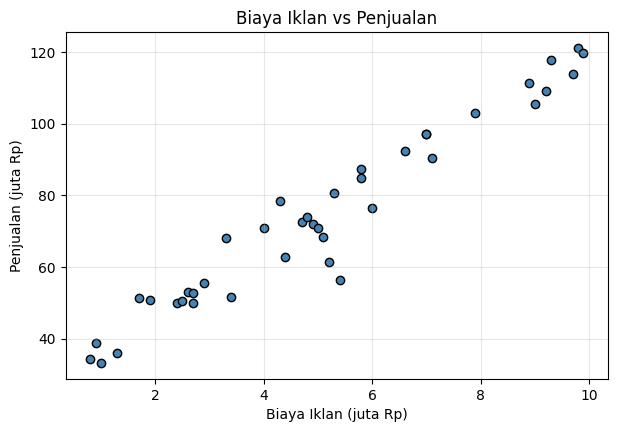

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

# Pisahkan X (2 dimensi, shape (n, 1)) dan y
X_ads = df_ads[["BiayaIklan"]].values      # double bracket -> 2D
y_ads = df_ads["Penjualan"].values
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

# Scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(X_ads, y_ads, color="steelblue", edgecolor="k")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones(X.shape[0]), X]            # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin = LinearRegression().fit(X_train, y_train)
b_ne, m_ne = lin.intercept_, lin.coef_[0]
print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X")

Intercept (b)  : 27.6131
Koefisien (m)  : 9.2416
Persamaan      : y_hat = 27.6131 + 9.2416 * X


**Jawaban A3 (interpretasi):**

Persamaan regresi hasil normal equation: **ŷ = 27,6131 + 9,2416 · X**.

Koefisien **m = 9,2416** berarti setiap kenaikan biaya iklan sebesar **1 juta Rp**, penjualan per bulan rata-rata naik sekitar **9,24 juta Rp** (dengan asumsi hubungan linear). Intercept **b = 27,6131** adalah penjualan dasar ketika biaya iklan 0. Karena biaya iklan terkecil pada data adalah 0,8 juta, nilai ini hanya berupa titik potong garis dan tidak perlu ditafsirkan terlalu harfiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin.predict(X_train)
y_pred_test = lin.predict(X_test)

hasil_a4 = pd.DataFrame({
    "MAE":  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    "MSE":  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    "RMSE": [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    "R2":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=["Training", "Testing"])
display(hasil_a4.round(4))
print("Std Penjualan (data train):", round(np.std(y_train), 4))

,MAE,MSE,RMSE,R2
Training,4.0062,26.3219,5.1305,0.9607
Testing,6.2916,75.4585,8.6867,0.8137


Std Penjualan (data train): 25.8794


**Jawaban A4 (analisis):**

| Data | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| Training | 4,0062 | 26,3219 | 5,1305 | 0,9607 |
| Testing | 6,2916 | 75,4585 | 8,6867 | 0,8137 |

**RMSE** adalah rata-rata kesalahan prediksi dalam satuan asli (juta Rp). Pada data testing RMSE = 8,69, artinya prediksi penjualan meleset sekitar 8,7 juta Rp, atau sekitar 10,5% dari rata-rata penjualan testing (82,7 juta). Nilai **R²** menunjukkan proporsi variasi penjualan yang dijelaskan oleh biaya iklan: 96,07% pada training dan 81,37% pada testing.

Model ini **sudah cukup baik**, karena satu variabel (biaya iklan) saja mampu menjelaskan lebih dari 80% variasi penjualan di data yang belum pernah dilihat, dan RMSE testing (8,69) jauh lebih kecil dari simpangan baku penjualan (±25,9). Meski begitu, ada selisih antara training dan testing (R² 0,96 vs 0,81). Data testing hanya 8 titik, sehingga angkanya sensitif terhadap pembagian data. Selisih ini juga menunjukkan bahwa performa pada data baru akan sedikit lebih buruk daripada performa training.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- learning rate = 0.001 ---


Intercept: 25.2720 | Koefisien: 9.6112 | MSE akhir: 27.6648
--- learning rate = 0.02 ---


Intercept: 27.6131 | Koefisien: 9.2416 | MSE akhir: 26.3219


--- learning rate = 0.1 ---


Intercept: nan | Koefisien: nan | MSE akhir: nan



/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_119/1773970267.py:16: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean(error ** 2))     # MSE
/tmp/ipykernel_119/1773970267.py:19: RuntimeWarning: overflow encountered in matmul
  self.coef_      -= self.lr * (2 / n) * (X.T @ error)
/tmp/ipykernel_119/1773970267.py:19: RuntimeWarning: invalid value encountered in subtract
  self.coef_      -= self.lr * (2 / n) * (X.T @ error)


,Model,LR,Intercept,Koefisien,MSE akhir (train)
0,Normal Equation,-,27.613127,9.241607,26.321944
1,Gradient Descent,0.001,25.271975,9.611181,27.664807
2,Gradient Descent,0.02,27.613127,9.241607,26.321944
3,Gradient Descent,0.1,NaN,NaN,NaN


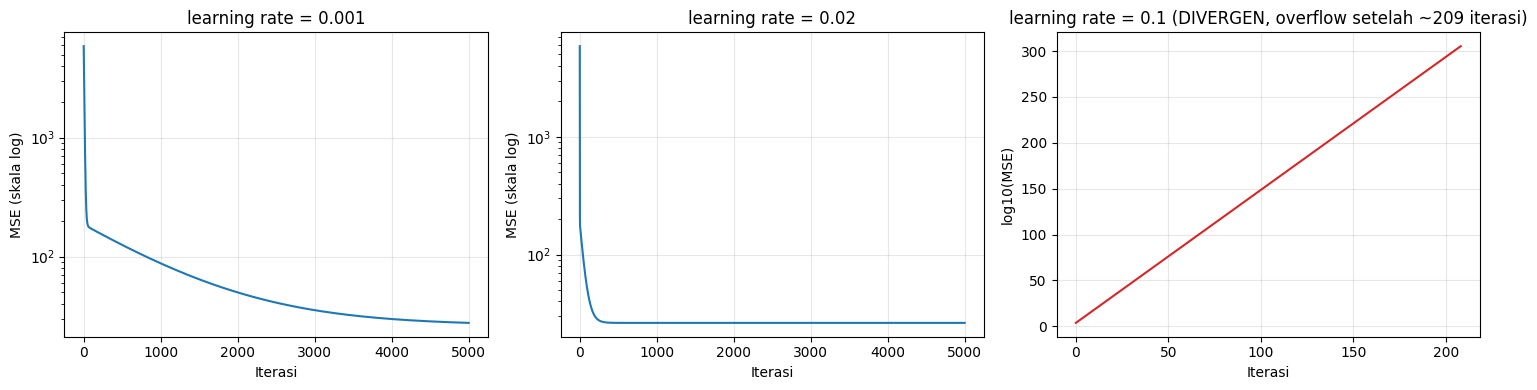

In [7]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (batch)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n = X.shape[0]
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history_ = []
        for _ in range(self.n_iter):
            y_hat = self.intercept_ + X @ self.coef_
            error = y_hat - y
            self.loss_history_.append(np.mean(error ** 2))     # MSE
            # gradien MSE
            self.intercept_ -= self.lr * (2 / n) * np.sum(error)
            self.coef_      -= self.lr * (2 / n) * (X.T @ error)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
rows = [{"Model": "Normal Equation", "LR": "-", "Intercept": b_ne, "Koefisien": m_ne,
         "MSE akhir (train)": mse(y_train, lin.predict(X_train))}]

for lr in learning_rates:
    print(f"--- learning rate = {lr} ---")
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    models_gd[lr] = gd
    print(f"Intercept: {gd.intercept_:.4f} | Koefisien: {gd.coef_[0]:.4f} | MSE akhir: {gd.loss_history_[-1]:.4f}")
    rows.append({"Model": "Gradient Descent", "LR": lr, "Intercept": gd.intercept_,
                 "Koefisien": gd.coef_[0], "MSE akhir (train)": gd.loss_history_[-1]})

print()
display(pd.DataFrame(rows))

# Grafik loss vs iterasi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(models_gd[lr].loss_history_, dtype=float)
    loss[~np.isfinite(loss)] = np.nan          # nilai inf/nan tidak digambar
    if lr < 0.05:
        ax.plot(loss)
        ax.set_yscale("log")
        ax.set_ylabel("MSE (skala log)")
    else:
        # loss divergen terlalu besar untuk skala log matplotlib -> gambar log10(MSE)
        ax.plot(np.log10(loss), color="tab:red")
        ax.set_ylabel("log10(MSE)")
        n_valid = np.isfinite(loss).sum()
        ax.set_title(f"learning rate = {lr} (DIVERGEN, overflow setelah ~{n_valid} iterasi)")
    if lr < 0.05:
        ax.set_title(f"learning rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

| Model | Intercept | Koefisien | MSE akhir (train) |
|---|---|---|---|
| Normal Equation | 27,6131 | 9,2416 | 26,3219 |
| GD, lr = 0,001 | 25,2720 | 9,6112 | 27,6648 |
| GD, lr = 0,02 | 27,6131 | 9,2416 | 26,3219 |
| GD, lr = 0,1 | NaN | NaN | NaN |

- **lr = 0,001 (terlalu lambat).** Loss turun mulus, tetapi setelah 5000 iterasi parameter (25,27 dan 9,61) masih berbeda dari solusi normal equation (27,61 dan 9,24), dan MSE (27,66) masih lebih tinggi dari 26,32. Langkahnya terlalu kecil, sehingga butuh iterasi jauh lebih banyak untuk konvergen.
- **lr = 0,02 (pas).** Hasilnya identik dengan normal equation sampai 4 desimal. Loss turun cepat dan sudah hampir mencapai nilai akhirnya (sekitar 26,32) pada iterasi ke-500-an, lalu datar.
- **lr = 0,1 (divergen).** Loss justru membesar: sekitar 1,8×10¹⁸ pada iterasi ke-10, lalu *overflow* pada iterasi sekitar ke-209, sehingga parameter menjadi `NaN`. Karena nilainya terlalu besar untuk skala log biasa, pada grafik lr = 0,1 yang digambar adalah log10(MSE), yang terlihat naik terus sampai putus saat overflow.

**Penyebabnya:** gradient descent untuk MSE hanya stabil jika *learning rate* lebih kecil dari 2/λmax, dengan λmax adalah nilai eigen terbesar dari (2/n)XᵀX. Pada data training ini λmax ≈ 63,1, sehingga batas stabilnya sekitar **0,032**. lr = 0,02 berada di bawah batas ini sehingga konvergen, sedangkan lr = 0,1 berada di atasnya. Setiap langkah melompati titik minimum dan mendarat lebih jauh dari sebelumnya, sehingga error terus membesar. Sementara itu lr = 0,001 stabil, tetapi laju konvergennya pada arah yang "datar" (nilai eigen terkecil ≈ 0,48) sangat lambat.

**Arti `RuntimeWarning: overflow`:** nilai error dan gradien menjadi begitu besar sehingga melampaui batas bilangan *float64* (sekitar 1,8×10³⁰⁸) dan menjadi `inf`. Operasi berikutnya (`inf − inf`) menghasilkan `NaN`. Ini tanda bahwa training gagal konvergen karena learning rate terlalu besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

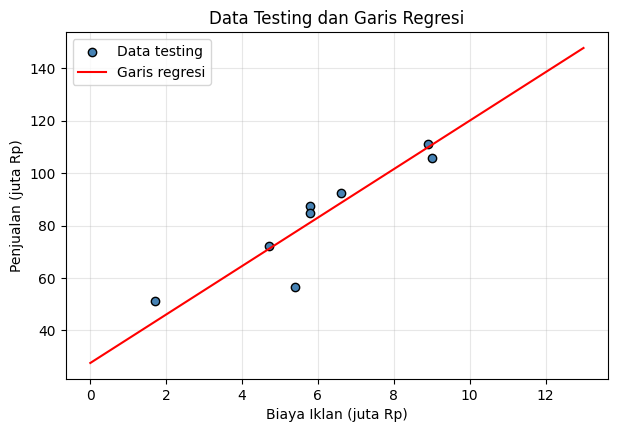

Biaya iklan  4.5 juta -> prediksi penjualan = 69.20 juta
Biaya iklan  7.0 juta -> prediksi penjualan = 92.30 juta
Biaya iklan 12.0 juta -> prediksi penjualan = 138.51 juta
Rentang BiayaIklan pada data: 0.8 s/d 9.9


In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi
x_line = np.linspace(0, 13, 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, color="steelblue", edgecolor="k", label="Data testing")
plt.plot(x_line, lin.predict(x_line), color="red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin.predict(biaya_baru)
for x, p in zip(biaya_baru.ravel(), pred_baru):
    print(f"Biaya iklan {x:>4} juta -> prediksi penjualan = {p:.2f} juta")
print("Rentang BiayaIklan pada data:", X_ads.min(), "s/d", X_ads.max())

**Jawaban A6 (analisis):**

Prediksi penjualan (model normal equation):

| Biaya iklan | Prediksi penjualan |
|---|---|
| 4,5 juta | 69,20 juta |
| 7 juta | 92,30 juta |
| 12 juta | 138,51 juta |

Prediksi untuk **4,5 juta** dan **7 juta** berada dalam rentang data (0,8–9,9 juta), sehingga cukup dapat dipercaya. Prediksi untuk **12 juta** adalah **ekstrapolasi** (di luar rentang data) dan kurang dapat dipercaya. Model hanya belajar dari biaya iklan 0,8–9,9 juta, dan hasil 138,5 juta sudah melebihi penjualan tertinggi di data (121,1 juta). Garis lurus mengasumsikan hubungan linear tetap berlaku selamanya, padahal di dunia nyata efek iklan biasanya mengalami *diminishing returns* (penambahan iklan memberi tambahan penjualan yang makin kecil) atau terbatas oleh ukuran pasar dan stok. Tidak ada data yang membuktikan pola linear tetap berlaku di atas 9,9 juta, sehingga angka ini hanya boleh dipakai sebagai perkiraan kasar.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah Spam (1)       : 25
Jumlah Bukan Spam (0) : 35
Shape X: (60, 2) | Shape y: (60,)


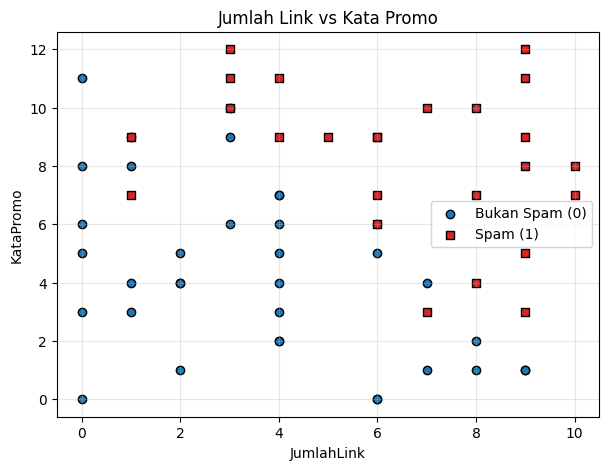

In [9]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())
print("Jumlah Spam (1)       :", (df_email["Spam"] == 1).sum())
print("Jumlah Bukan Spam (0) :", (df_email["Spam"] == 0).sum())

X_em = df_email[["JumlahLink", "KataPromo"]].values
y_em = df_email["Spam"].values
print("Shape X:", X_em.shape, "| Shape y:", y_em.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_em[y_em == 0, 0], X_em[y_em == 0, 1], c="tab:blue", edgecolor="k", label="Bukan Spam (0)")
plt.scatter(X_em[y_em == 1, 0], X_em[y_em == 1, 1], c="tab:red", marker="s", edgecolor="k", label="Spam (1)")
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2) | Test: (15, 2)


Intercept (b)       : -10.1635
Koefisien m1 (Link) : 0.8950
Koefisien m2 (Promo): 0.8434
P(Spam) = sigmoid(-10.1635 + 0.8950*JumlahLink + 0.8434*KataPromo)
Log loss awal: 0.6931 | akhir: 0.2844


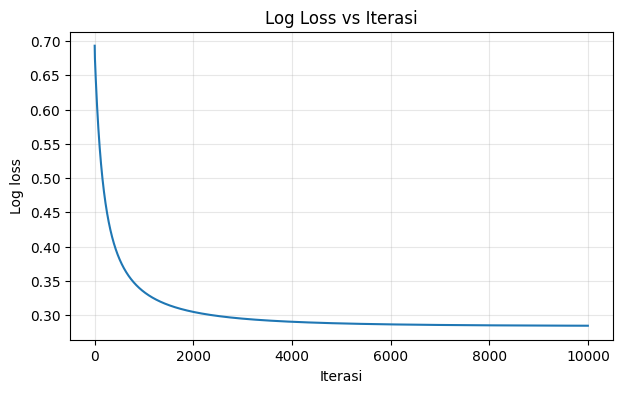

In [10]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_em, y_em, test_size=0.25, random_state=RANDOM_STATE)
print("Train:", Xe_train.shape, "| Test:", Xe_test.shape)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (log loss)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n = X.shape[0]
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history_ = []
        eps = 1e-15
        for _ in range(self.n_iter):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, eps, 1 - eps)
            self.loss_history_.append(-np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip)))
            # gradien log loss
            error = p - y
            self.intercept_ -= self.lr * np.mean(error)
            self.coef_      -= self.lr * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

logreg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)
b_lg = logreg.intercept_
m1_lg, m2_lg = logreg.coef_
print(f"Intercept (b)       : {b_lg:.4f}")
print(f"Koefisien m1 (Link) : {m1_lg:.4f}")
print(f"Koefisien m2 (Promo): {m2_lg:.4f}")
print(f"P(Spam) = sigmoid({b_lg:.4f} + {m1_lg:.4f}*JumlahLink + {m2_lg:.4f}*KataPromo)")
print(f"Log loss awal: {logreg.loss_history_[0]:.4f} | akhir: {logreg.loss_history_[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(logreg.loss_history_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Hasil training (lr = 0,1; 10.000 iterasi):

**P(Spam) = σ(−10,1635 + 0,8950 · JumlahLink + 0,8434 · KataPromo)**

Kedua koefisien positif: semakin banyak link dan kata promosi, semakin besar peluang email dianggap spam. Setiap tambahan 1 link menaikkan *odds* spam sekitar e^0,8950 ≈ 2,45 kali, dan setiap tambahan 1 kata promosi sekitar e^0,8434 ≈ 2,32 kali. Pengaruh keduanya hampir sama kuat, dengan jumlah link sedikit lebih besar.

**Grafik log loss:** loss turun tajam dari 0,6931 (= ln 2, saat semua probabilitas 0,5) menjadi 0,3821 pada iterasi ke-500 dan 0,3045 pada iterasi ke-2000, lalu melandai sampai 0,2844 di akhir (0,2877 pada iterasi ke-5000). Jadi loss **sudah turun dan praktis stabil**, hanya masih menurun sangat pelan pada ujung iterasi.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred = logreg.predict(Xe_test)
cm = confusion_matrix(ye_test, ye_pred)
print("Accuracy :", round(accuracy_score(ye_test, ye_pred), 4))
print("Precision:", round(precision_score(ye_test, ye_pred), 4))
print("Recall   :", round(recall_score(ye_test, ye_pred), 4))
print("F1-score :", round(f1_score(ye_test, ye_pred), 4))
print("\nConfusion matrix (baris=aktual, kolom=prediksi):")
display(pd.DataFrame(cm, index=["Aktual 0 (Bukan Spam)", "Aktual 1 (Spam)"],
                     columns=["Prediksi 0", "Prediksi 1"]))
print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

Accuracy : 0.8667
Precision: 0.8333
Recall   : 0.8333
F1-score : 0.8333

Confusion matrix (baris=aktual, kolom=prediksi):


,Prediksi 0,Prediksi 1
Aktual 0 (Bukan Spam),8,1
Aktual 1 (Spam),1,5


TN=8  FP=1  FN=1  TP=5


**Jawaban B3 (analisis):**

Hasil pada data testing (15 email): **accuracy = 0,8667**, **precision = 0,8333**, **recall = 0,8333**, **F1 = 0,8333**.

| | Prediksi Bukan Spam | Prediksi Spam |
|---|---|---|
| **Aktual Bukan Spam** | TN = 8 | FP = 1 |
| **Aktual Spam** | FN = 1 | TP = 5 |

- **FP (false positive):** email yang sebenarnya *bukan spam* tetapi dianggap spam. Pada data ini ada 1 email.
- **FN (false negative):** email yang sebenarnya *spam* tetapi lolos ke inbox. Pada data ini ada 1 email.

Menurut saya **FP lebih merugikan**. Email penting yang salah masuk folder spam, misalnya tagihan, undangan wawancara, atau informasi akademik, bisa terlewat dan menimbulkan kerugian nyata. FN hanya membuat pengguna menerima satu email gangguan yang bisa dihapus manual. Karena itu, untuk filter spam, **precision** perlu mendapat perhatian lebih dibanding recall.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-10.1635 + 0.8950 * x1) / 0.8434
                   x2 = 12.0513 + (-1.0612) * x1


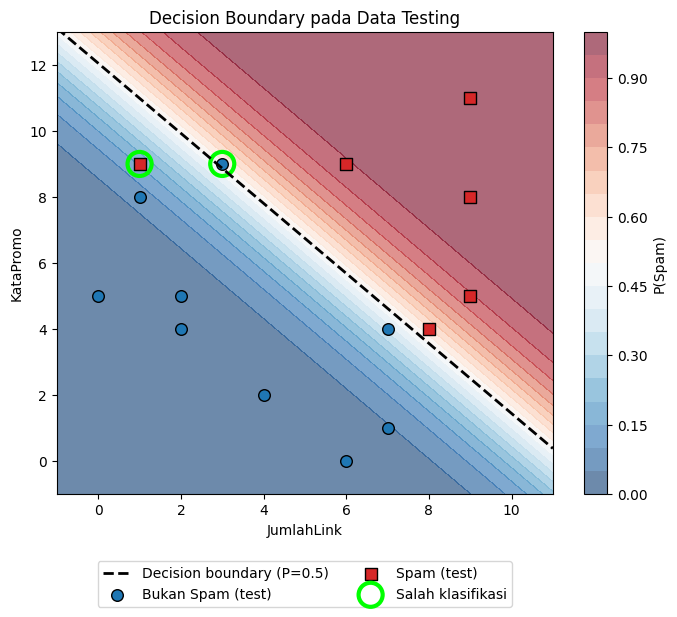

Jumlah data testing salah klasifikasi: 2 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,1,9,1,0,0.1573
1,3,9,0,1,0.5279


In [12]:
# Jawaban B4
# 1. Persamaan decision boundary
print(f"Decision boundary: x2 = -({b_lg:.4f} + {m1_lg:.4f} * x1) / {m2_lg:.4f}")
print(f"                   x2 = {-b_lg/m2_lg:.4f} + ({-m1_lg/m2_lg:.4f}) * x1")

# 2. Visualisasi data testing + background probabilitas + garis boundary
x1_min, x1_max = 0 - 1, 10 + 1
x2_min, x2_max = 0 - 1, 12 + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = logreg.predict_proba(grid).reshape(xx1.shape)

salah = ye_pred != ye_test      # 3. data salah klasifikasi

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")
x_b = np.linspace(x1_min, x1_max, 100)
plt.plot(x_b, -(b_lg + m1_lg * x_b) / m2_lg, "k--", linewidth=2, label="Decision boundary (P=0.5)")
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], c="tab:blue", edgecolor="k", s=70, label="Bukan Spam (test)")
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], c="tab:red", marker="s", edgecolor="k", s=70, label="Spam (test)")
if salah.any():
    plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=300, facecolors="none",
                edgecolors="lime", linewidths=3, label="Salah klasifikasi")
plt.xlim(x1_min, x1_max); plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
plt.show()

print("Jumlah data testing salah klasifikasi:", salah.sum(), "dari", len(ye_test))
if salah.any():
    display(pd.DataFrame({
        "JumlahLink": Xe_test[salah, 0], "KataPromo": Xe_test[salah, 1],
        "Aktual": ye_test[salah], "Prediksi": ye_pred[salah],
        "P(Spam)": logreg.predict_proba(Xe_test[salah]).round(4)}))

**Jawaban B4 (analisis):**

Decision boundary: **x₂ = −(−10,1635 + 0,8950·x₁) / 0,8434 = 12,0513 − 1,0612·x₁**. Secara kasar, email diprediksi spam jika jumlah link ditambah jumlah kata promosi bernilai sekitar 12 atau lebih. Titik di atas/kanan garis diprediksi Spam, dan di bawah/kiri garis diprediksi Bukan Spam.

Terdapat **2 dari 15** data testing yang salah diklasifikasikan (ditandai lingkaran hijau pada grafik):

| JumlahLink | KataPromo | Aktual | Prediksi | P(Spam) | Jenis |
|---|---|---|---|---|---|
| 1 | 9 | 1 (Spam) | 0 | 0,1573 | FN |
| 3 | 9 | 0 (Bukan Spam) | 1 | 0,5279 | FP |

Email (1, 9) adalah spam, tetapi jumlah linknya hanya 1 sehingga skor totalnya berada jauh di sisi "bukan spam". Email (3, 9) berada sangat dekat dengan garis batas (P = 0,53), sehingga sedikit saja pergeseran garis sudah mengubah prediksinya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = logreg.predict_proba(Xe_test)
rows = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    c = confusion_matrix(ye_test, pred)
    rows.append({"Threshold": th, "TN": c[0, 0], "FP": c[0, 1], "FN": c[1, 0], "TP": c[1, 1],
                 "Accuracy": accuracy_score(ye_test, pred),
                 "Precision": precision_score(ye_test, pred),
                 "Recall": recall_score(ye_test, pred)})
tabel_th = pd.DataFrame(rows)
display(tabel_th.round(4))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall
0,0.3,7,2,1,5,0.8000,0.7143,0.8333
1,0.5,8,1,1,5,0.8667,0.8333,0.8333
2,0.7,9,0,2,4,0.8667,1.0000,0.6667


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall |
|---|---|---|---|---|---|---|---|
| 0,3 | 7 | 2 | 1 | 5 | 0,8000 | 0,7143 | 0,8333 |
| 0,5 | 8 | 1 | 1 | 5 | 0,8667 | 0,8333 | 0,8333 |
| 0,7 | 9 | 0 | 2 | 4 | 0,8667 | 1,0000 | 0,6667 |

**Pengaruh threshold:** menaikkan threshold membuat model lebih "hati-hati" memberi label spam. FP berkurang sehingga **precision naik** (0,71 → 0,83 → 1,0), tetapi lebih banyak spam yang lolos (FN naik) sehingga **recall turun** (0,83 → 0,83 → 0,67). Menurunkan threshold berefek sebaliknya: lebih banyak spam tertangkap, tetapi lebih banyak email normal salah dianggap spam sehingga precision turun. Jadi precision dan recall saling tukar (*trade-off*).

**Threshold pilihan: 0,7.** Berdasarkan B3, FP (email penting masuk spam) lebih merugikan daripada FN. Threshold 0,7 membuat **tidak ada** email normal yang salah masuk spam (FP = 0, precision = 1,0) dengan akurasi yang tetap sama dengan threshold 0,5 (0,8667). Harganya, recall turun menjadi 0,67 (2 dari 6 spam lolos), yang menurut saya masih dapat diterima karena spam yang lolos hanya mengganggu. Perlu diingat bahwa test set hanya 15 email, sehingga angka ini hanya gambaran kasar.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7   # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
p_baru = logreg.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = p_baru.round(4)
email_baru["Prediksi"] = np.where(p_baru >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
display(email_baru)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0005,Bukan Spam
1,E2,5,6,0.3478,Bukan Spam
2,E3,9,10,0.9982,Spam
3,E4,2,11,0.7116,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena outputnya adalah probabilitas kelas yang kemudian diubah menjadi label diskret (Spam/Bukan Spam) dengan threshold, bukan nilai kontinu. Kata "regression" berasal dari komponen awalnya yang berupa kombinasi linear z = b + m₁x₁ + m₂x₂. Fungsi **sigmoid** σ(z) = 1/(1+e⁻ᶻ) memetakan nilai z yang bisa berapa saja ke rentang (0, 1) sehingga bisa ditafsirkan sebagai peluang. Z positif besar menghasilkan peluang mendekati 1, z negatif besar mendekati 0, dan z = 0 menghasilkan tepat 0,5 (batas keputusan).

**Jawaban C2:**
**Normal equation** menghitung parameter optimal secara langsung (satu kali hitung) lewat rumus θ = (XᵀX)⁻¹Xᵀy, tanpa learning rate dan tanpa iterasi. **Gradient descent** mencari parameter secara bertahap dengan menggeser parameter berlawanan arah gradien loss selama banyak iterasi, dan hasilnya bergantung pada learning rate dan jumlah iterasi (seperti terlihat di A5). Gradient descent sebaiknya dipakai ketika data atau jumlah fitur sangat besar, karena membalik matriks XᵀX mahal (sekitar O(n³) terhadap jumlah fitur). Gradient descent juga dipakai ketika modelnya tidak punya solusi tertutup, seperti Logistic Regression.

**Jawaban C3:**
Data training sudah dipakai model untuk belajar, sehingga skor di data training cenderung terlalu optimis (model bisa saja hanya menghafal). Tujuan sebenarnya adalah performa pada data baru, yang hanya bisa diukur pada **data testing** yang tidak dilihat saat training. **Overfitting** adalah kondisi saat model terlalu menyesuaikan diri pada data training (termasuk noise) sehingga performanya bagus di training tetapi buruk di data baru. Pada A4, R² training 0,9607 lebih tinggi dari R² testing 0,8137, yang merupakan contoh selisih semacam itu.

**Jawaban C4:**
Linear Regression memprediksi nilai kontinu, sehingga ukuran kesalahan yang wajar adalah jarak kuadrat antara nilai prediksi dan nilai aktual (MSE). Logistic Regression mengeluarkan probabilitas p di antara 0 dan 1 untuk label biner. Ukuran yang cocok adalah **log loss** (cross-entropy), −[y·log(p) + (1−y)·log(1−p)], karena menghukum sangat berat prediksi yang yakin tetapi salah (misal p ≈ 0 padahal aslinya 1). Log loss juga berasal dari prinsip *maximum likelihood* untuk data biner, dan bersifat konveks bila dikombinasikan dengan sigmoid. Jika MSE dipakai dengan sigmoid, permukaan loss menjadi tidak konveks dan gradiennya mengecil saat prediksi salah-yakin, sehingga training lambat.

**Jawaban C5:**
Setiap mahasiswa memakai `random_state` berbeda (dua digit terakhir NIM), sehingga pembagian data training dan testing berbeda, termasuk titik data mana yang masuk ke test set. Akibatnya koefisien, error, dan akurasi berbeda walau dataset dan algoritmanya sama. Pada dataset sekecil ini (40 dan 60 data), satu atau dua titik berbeda saja sudah bisa mengubah hasil secara cukup terlihat. Itulah mengapa hasil evaluasi pada satu split sebaiknya tidak dianggap sebagai kebenaran mutlak.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinear
from sklearn.linear_model import LogisticRegression as SkLogistic

# --- Linear Regression ---
sk_lin = SkLinear().fit(X_train, y_train)
print("== Linear Regression ==")
print(f"Buatan sendiri : b={lin.intercept_:.6f}, m={lin.coef_[0]:.6f}, R2 test={r2_score(y_test, lin.predict(X_test)):.6f}")
print(f"scikit-learn   : b={sk_lin.intercept_:.6f}, m={sk_lin.coef_[0]:.6f}, R2 test={r2_score(y_test, sk_lin.predict(X_test)):.6f}")

# --- Logistic Regression ---
sk_log_default = SkLogistic(max_iter=10000).fit(Xe_train, ye_train)                  # default: L2, C=1.0
sk_log_nopen   = SkLogistic(C=np.inf, max_iter=10000).fit(Xe_train, ye_train)    # tanpa regularisasi (C=inf)

print("\n== Logistic Regression ==")
hasil_lg = pd.DataFrame({
    "Intercept": [b_lg, sk_log_default.intercept_[0], sk_log_nopen.intercept_[0]],
    "m1 (Link)": [m1_lg, sk_log_default.coef_[0, 0], sk_log_nopen.coef_[0, 0]],
    "m2 (Promo)": [m2_lg, sk_log_default.coef_[0, 1], sk_log_nopen.coef_[0, 1]],
    "Accuracy test": [accuracy_score(ye_test, logreg.predict(Xe_test)),
                      accuracy_score(ye_test, sk_log_default.predict(Xe_test)),
                      accuracy_score(ye_test, sk_log_nopen.predict(Xe_test))],
}, index=["Buatan sendiri (tanpa regularisasi)", "sklearn default (L2, C=1.0)", "sklearn tanpa regularisasi (C=inf)"])
display(hasil_lg.round(4))

== Linear Regression ==
Buatan sendiri : b=27.613127, m=9.241607, R2 test=0.813662
scikit-learn   : b=27.613127, m=9.241607, R2 test=0.813662

== Logistic Regression ==


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,Intercept,m1 (Link),m2 (Promo),Accuracy test
Buatan sendiri (tanpa regularisasi),-10.1635,0.8950,0.8434,0.8667
"sklearn default (L2, C=1.0)",-9.4055,0.8177,0.7843,0.8667
sklearn tanpa regularisasi (C=inf),-10.8933,0.9650,0.8992,0.8667


**Jawaban Bonus (analisis):**

**Linear Regression:** hasil scikit-learn **identik** dengan implementasi sendiri (b = 27,613127; m = 9,241607; R² testing = 0,813662), karena keduanya menyelesaikan masalah least squares yang sama secara eksak.

**Logistic Regression:**

| Model | Intercept | m₁ (Link) | m₂ (Promo) | Accuracy test |
|---|---|---|---|---|
| Buatan sendiri (tanpa regularisasi) | −10,1635 | 0,8950 | 0,8434 | 0,8667 |
| sklearn default (L2, C = 1,0) | −9,4055 | 0,8177 | 0,7843 | 0,8667 |
| sklearn tanpa regularisasi (C = ∞) | −10,8933 | 0,9650 | 0,8992 | 0,8667 |

Koefisien sklearn default **berbeda** dari implementasi sendiri. Penyebab utamanya: `LogisticRegression` di scikit-learn secara default memakai **regularisasi L2 dengan C = 1,0**, yang menambahkan penalti pada besar koefisien sehingga koefisien "diperkecil" (0,82 dan 0,78 dibanding 0,90 dan 0,84). Implementasi sendiri tidak memakai regularisasi. Ketika regularisasi dimatikan (C = ∞), koefisien sklearn menjadi lebih dekat dengan milik kita, tetapi masih sedikit berbeda (0,97 dan 0,90). Ini karena data hampir terpisah linear, sehingga log loss terus menurun pelan dan koefisien optimal cenderung terus membesar. Gradient descent kita berhenti di 10.000 iterasi (loss masih turun sedikit), sedangkan solver sklearn berjalan lebih jauh hingga kriteria konvergensinya. Meskipun koefisiennya berbeda, **akurasi testing ketiganya sama (0,8667)**, karena garis keputusan yang dihasilkan hampir sama.